# Real Hiring Funnel Analysis

This notebook studies a real company's recruitment tracker, to see where candidates drop out of a manual hiring process. That is the problem JobMatch AI's automatic screening is meant to ease.

**Privacy.** The tracker holds personal details, so the file is kept in `data/private/`, which is excluded from Git. The first step drops every column that identifies a person (names, emails, phone numbers, interviewer and recruiter names, free-text remarks). Only counts and rates are shown.

To run it, put the workbook at `data/private/Recruitment_Tracker.xlsx`.

In [1]:
from pathlib import Path
import re
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

sns.set_theme(style="whitegrid")
SOURCE = Path("data/private/Recruitment_Tracker.xlsx")
FIGURES = Path("figures"); FIGURES.mkdir(exist_ok=True)

## 1. Load and anonymise

In [2]:
raw = pd.read_excel(SOURCE, sheet_name="Master Candidate Tracker", header=1)
raw = raw.dropna(subset=["Candidate Name"])
PERSONAL = ["Candidate Name", "Mobile No", "Email ID", "Recruiter", "Current Organization",
            "L1 Interviewer", "L2 Interviewer", "L3 Interviewer", "L4 Interviewer",
            "L1 Status / Feedback", "L2 Status / Feedback", "L3 Status / Feedback", "L4 Status / Feedback",
            "Remarks / Next Step", "Sr No"]
df = raw.drop(columns=[c for c in PERSONAL if c in raw.columns]).reset_index(drop=True)
del raw
df["Role"] = df["Role / Position"].fillna("Unspecified")
df["Source"] = df["Source"].str.strip().str.title().fillna("Not recorded").replace(
    {"Others": "Other", "Refferal": "Referral"})
print(f"{len(df):,} candidates, {df.shape[1]} non-identifying columns kept")
print(sorted(df.columns))

1,088 candidates, 25 non-identifying columns kept
['Current CTC', 'Current Location', 'Current Status', 'Expected CTC (ECTC)', 'Final Status', 'Joining Date', 'L1 Result', 'L1 Scheduled Date', 'L2 Result', 'L2 Scheduled Date', 'L3 Result', 'L3 Scheduled Date', 'L4 Result', 'L4 Scheduled Date', 'Notice Period', 'Offer CTC', 'Offer Rollout Date', 'Preferred Location', 'Role', 'Role / Position', 'Screening Date', 'Screening Status', 'Source', 'Status Updated Date', 'Total Experience']


## 2. Candidates per role

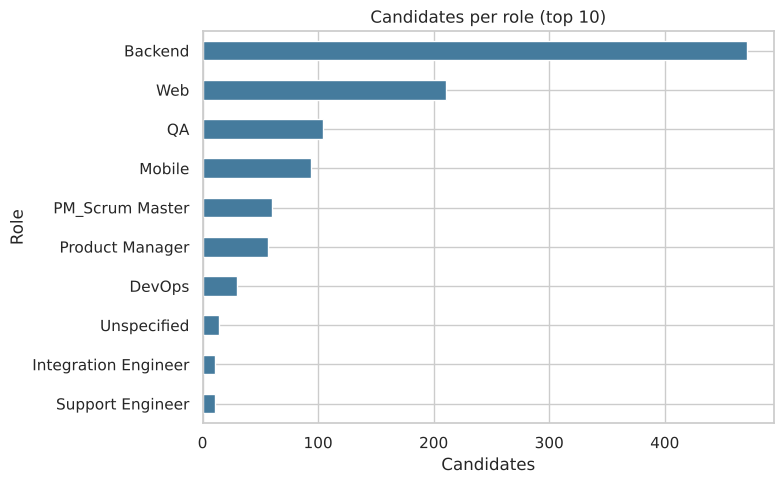

,% of candidates
Role,
Backend,43.3
Web,19.4
QA,9.6
Mobile,8.6
PM_Scrum Master,5.5
Product Manager,5.2
DevOps,2.8
Unspecified,1.3
Integration Engineer,1.0


In [3]:
roles = df["Role"].value_counts()
ax = roles.head(10).sort_values().plot(kind="barh", figsize=(8, 5), color="#457b9d")
ax.set_title("Candidates per role (top 10)"); ax.set_xlabel("Candidates")
plt.tight_layout(); plt.savefig(FIGURES / "funnel_roles.png", dpi=150); plt.show()
(roles / len(df) * 100).round(1).head(10).rename("% of candidates").to_frame()

## 3. The hiring funnel\nHow many candidates reached each stage, and how many were selected at each interview round.

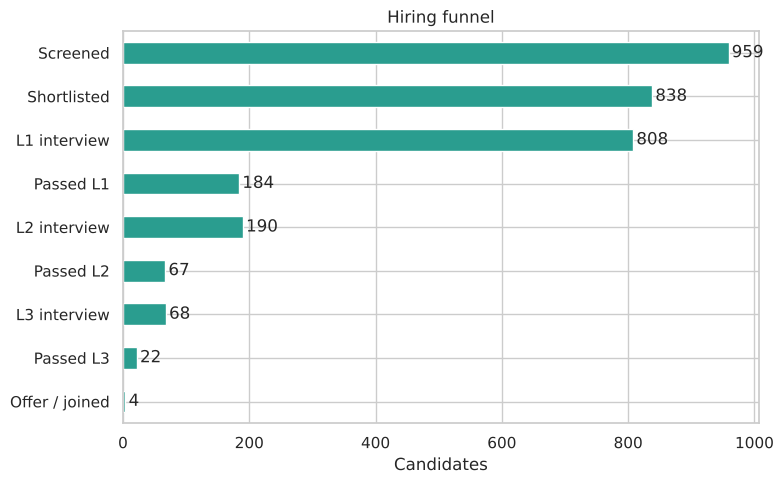

,Candidates,% of screened
Screened,959,100.0
Shortlisted,838,87.4
L1 interview,808,84.3
Passed L1,184,19.2
L2 interview,190,19.8
Passed L2,67,7.0
L3 interview,68,7.1
Passed L3,22,2.3
Offer / joined,4,0.4


In [4]:
stages = {
    "Screened": df["Screening Date"].notna(),
    "Shortlisted": df["Screening Status"].isin(["Shortlisted", "Selected"]),
    "L1 interview": df["L1 Scheduled Date"].notna(),
    "Passed L1": df["L1 Result"].eq("Selected"),
    "L2 interview": df["L2 Scheduled Date"].notna(),
    "Passed L2": df["L2 Result"].eq("Selected"),
    "L3 interview": df["L3 Scheduled Date"].notna(),
    "Passed L3": df["L3 Result"].eq("Selected"),
    "Offer / joined": df["Final Status"].isin(["Offer Extended", "Joined", "Selected"]),
}
funnel = pd.DataFrame({"Candidates": {k: int(v.sum()) for k, v in stages.items()}})
funnel["% of screened"] = (funnel["Candidates"] / funnel.loc["Screened", "Candidates"] * 100).round(1)
ax = funnel["Candidates"][::-1].plot(kind="barh", figsize=(8, 5), color="#2a9d8f")
for i, v in enumerate(funnel["Candidates"][::-1]):
    ax.text(v + 5, i, f"{v}", va="center")
ax.set_title("Hiring funnel"); ax.set_xlabel("Candidates")
plt.tight_layout(); plt.savefig(FIGURES / "funnel_stages.png", dpi=150); plt.show()
funnel

## 4. Interview outcomes by round

In [5]:
rounds = {}
for r in ["L1", "L2", "L3", "L4"]:
    res = df[f"{r} Result"].dropna()
    rounds[r] = {"Outcomes recorded": len(res), "Selected": int((res == "Selected").sum()),
                 "Rejected": int((res == "Rejected").sum()), "No show / on hold": int(res.isin(["No Show", "On Hold"]).sum())}
rounds = pd.DataFrame(rounds).T
rounds["Selection rate %"] = (rounds["Selected"] / rounds["Outcomes recorded"] * 100).round(1)
rounds

,Outcomes recorded,Selected,Rejected,No show / on hold,Selection rate %
L1,271,184,83,4,67.9
L2,97,67,29,1,69.1
L3,24,22,2,0,91.7
L4,4,3,1,0,75.0


In [6]:
l1 = df.dropna(subset=["L1 Result"]).groupby("Role")["L1 Result"].agg(
    outcomes="count", selected=lambda s: (s == "Selected").sum())
l1 = l1[l1.outcomes >= 10]
l1["L1 selection rate %"] = (l1.selected / l1.outcomes * 100).round(1)
l1.sort_values("outcomes", ascending=False)

,outcomes,selected,L1 selection rate %
Role,,,
Backend,143,72,50.3
Web,46,46,100.0
Mobile,23,23,100.0
Product Manager,21,9,42.9
PM_Scrum Master,15,11,73.3
QA,13,13,100.0


## 5. Where the pipeline stalls\nCandidates still waiting for interview feedback are a sign of manual bottlenecks.

922 of 1,088 candidates (85%) are waiting on a pending, in-process or not-started step.


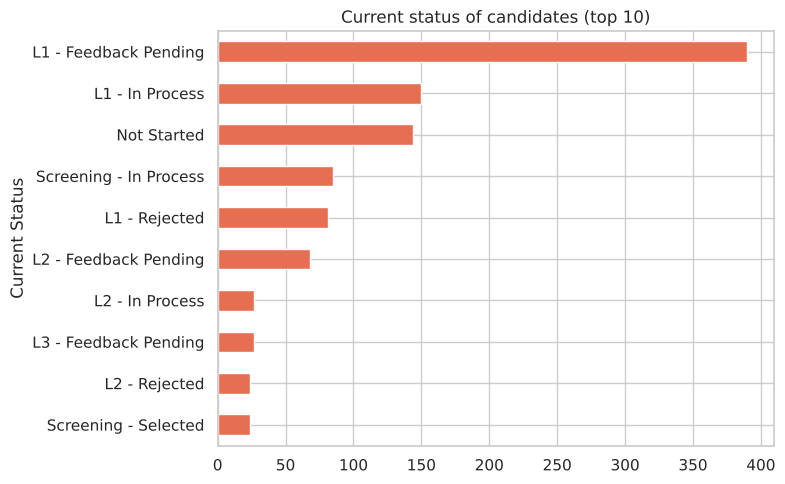

,Candidates
Final Status,
In Process,803
Not recorded,144
Rejected,127
Backed Out,9
Offer Extended,2
Joined,1
On Hold,1
Selected,1


In [7]:
status = df["Current Status"].value_counts()
pending = status[status.index.str.contains("Pending|In Process|Not Started", regex=True)].sum()
print(f"{pending:,} of {len(df):,} candidates ({pending / len(df):.0%}) are waiting on a pending, in-process or not-started step.")
ax = status.head(10).sort_values().plot(kind="barh", figsize=(8, 5), color="#e76f51")
ax.set_title("Current status of candidates (top 10)")
plt.tight_layout(); plt.savefig(FIGURES / "funnel_current_status.png", dpi=150); plt.show()
final = df["Final Status"].fillna("Not recorded").value_counts()
final.rename("Candidates").to_frame()

## 6. Sourcing channels and monthly volume

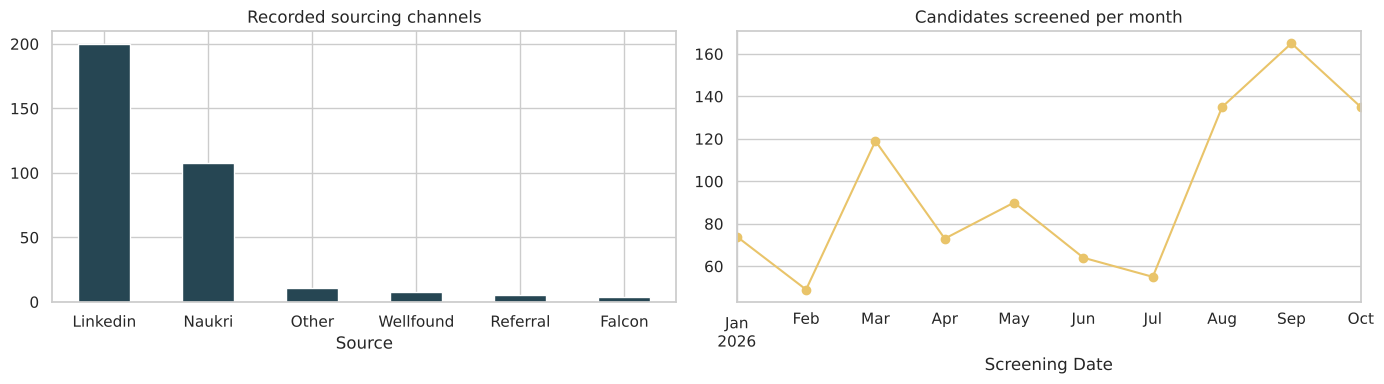

Source recorded for 354 of 1088 candidates


In [8]:
sources = df.loc[df["Source"] != "Not recorded", "Source"].value_counts()
fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sources.head(6).plot(kind="bar", ax=axes[0], rot=0, color="#264653"); axes[0].set_title("Recorded sourcing channels")
monthly = pd.to_datetime(df["Screening Date"], errors="coerce").dt.to_period("M").value_counts().sort_index()
monthly.plot(kind="line", marker="o", ax=axes[1], color="#e9c46a"); axes[1].set_title("Candidates screened per month")
plt.tight_layout(); plt.savefig(FIGURES / "funnel_sources_monthly.png", dpi=150); plt.show()
print(f"Source recorded for {sources.sum()} of {len(df)} candidates")

## 7. Data quality

In [9]:
quality = (df.notna().mean() * 100).round(1).sort_values()
quality.rename("% filled").to_frame().head(15)

,% filled
Status Updated Date,0.0
Offer CTC,0.1
Joining Date,0.1
Offer Rollout Date,0.1
L4 Result,0.4
L4 Scheduled Date,2.1
L3 Result,2.2
L3 Scheduled Date,6.2
L2 Result,8.9
L2 Scheduled Date,17.5


## 8. Findings

* The process is very top-heavy. Recruiters screen and shortlist a large number of candidates, but only a small share get through the interview rounds to an offer.
* A large share of candidates are left waiting at "feedback pending" or "in process", which shows how much manual effort each shortlist creates.
* Far more L1 interviews are scheduled than have a recorded result, so interview feedback is often never captured.
* Selection rates at L1 differ between roles, so the quality of shortlists differs too.
* Important fields such as experience, salary and notice period are filled in for only about a third of candidates, so manual tracking loses information.

**What this means for JobMatch AI:** automatic scoring at the moment of application gives recruiters a ranked, explained shortlist. That should cut the number of weak candidates sent to L1 interviews and reduce the feedback backlog. Because every application is stored with its parsed details, the data-quality gaps seen here would not occur.